# Nº 11 · La régression linéaire

*θ Théta, le Machine Learning, une notion à la fois.*

Une régression linéaire écrite de zéro, sur les vraies ventes de maisons d'Ames (Iowa, 2006 à 2010) :

1. préparer les données ;
2. écrire la prédiction, le coût et le gradient ;
3. entraîner, et retrouver les chiffres de l'épisode ;
4. comparer avec la formule directe et avec scikit-learn ;
5. voir la limite : une droite ne suit pas une relation courbe.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Les données

Le fichier vient de De Cock (2011). Comme le recommande l'auteur, on écarte les maisons de plus de 4 000 pieds
carrés. La surface passe en centaines de m², le prix en millions de FCFA, au cours du 27 octobre 2026
(1 dollar = 588,30 FCFA).

Si le fichier local est absent, le notebook lit la source d'origine.

In [2]:
LOCAL = Path("donnees/ames-maisons.csv.gz")
ORIGINE = "http://jse.amstat.org/v19n3/decock/AmesHousing.txt"

ventes = pd.read_csv(LOCAL) if LOCAL.exists() else pd.read_csv(ORIGINE, sep="\t")
ventes = ventes[ventes["Gr Liv Area"] <= 4000]

x = ventes["Gr Liv Area"].to_numpy() * 0.09290304 / 100
y = ventes["SalePrice"].to_numpy() * 588.30 / 1e6

print(f"{len(x)} ventes ; surface moyenne {x.mean() * 100:.0f} m² ; prix moyen {y.mean():.1f} millions de FCFA")
assert len(x) == 2925

2925 ventes ; surface moyenne 139 m² ; prix moyen 106.1 millions de FCFA


## 2. Prédiction, coût, gradient

- la prédiction : ŷ = w·x + b ;
- le coût, la MSE de l'épisode 05 : J = (1/n) Σ (ŷᵢ − yᵢ)² ;
- le gradient : la pente de J selon w vaut (2/n) Σ (ŷᵢ − yᵢ)·xᵢ, selon b (2/n) Σ (ŷᵢ − yᵢ).

In [3]:
def predire(x, w, b):
    return w * x + b


def cout(x, y, w, b):
    return np.mean((predire(x, w, b) - y) ** 2)


def gradient(x, y, w, b):
    erreur = predire(x, w, b) - y
    return 2 * np.mean(erreur * x), 2 * np.mean(erreur)

On vérifie le gradient sans se fier à la formule : une dérivée se retrouve par un petit écart sur chaque réglage.

In [4]:
w_essai, b_essai, h = 10.0, 5.0, 1e-5
numerique = ((cout(x, y, w_essai + h, b_essai) - cout(x, y, w_essai - h, b_essai)) / (2 * h),
             (cout(x, y, w_essai, b_essai + h) - cout(x, y, w_essai, b_essai - h)) / (2 * h))
print("gradient calculé :", np.round(gradient(x, y, w_essai, b_essai), 3))
print("gradient numérique :", np.round(numerique, 3))
assert np.allclose(gradient(x, y, w_essai, b_essai), numerique, atol=1e-3)

gradient calculé : [-268.167 -174.513]
gradient numérique : [-268.167 -174.513]


## 3. L'entraînement

Le modèle part ici de w = 0 et b = 0, pour lire le progrès. En pratique, le départ est tiré au hasard près de zéro.

In [5]:
def entrainer(x, y, eta, iterations, w=0.0, b=0.0):
    """Renvoie {itération : (w, b, coût)}."""
    historique = {0: (w, b, cout(x, y, w, b))}
    for k in range(1, iterations + 1):
        dw, db = gradient(x, y, w, b)
        w, b = w - eta * dw, b - eta * db
        historique[k] = (w, b, cout(x, y, w, b))
    return historique


historique = entrainer(x, y, eta=0.2, iterations=1000)
for k in (0, 10, 100, 1000):
    w, b, j = historique[k]
    print(f"itération {k:>4} : w = {w:5.1f}, b = {b:4.1f}, J = {j:,.0f}".replace(",", " "))

itération    0 : w =   0.0  b =  0.0  J = 13 400
itération   10 : w =  57.5  b = 27.9  J = 1 085
itération  100 : w =  72.2  b =  6.1  J = 1 030
itération 1000 : w =  73.6  b =  4.0  J = 1 030


Ces chiffres sont ceux de la page Comparaison de l'épisode.

In [6]:
attendus = {0: (0.0, 0.0, 13400), 10: (57.5, 27.9, 1085), 100: (72.2, 6.1, 1030), 1000: (73.6, 4.0, 1030)}
for k, (w_vu, b_vu, j_vu) in attendus.items():
    w, b, j = historique[k]
    assert (round(w, 1), round(b, 1), round(j)) == (w_vu, b_vu, j_vu), k

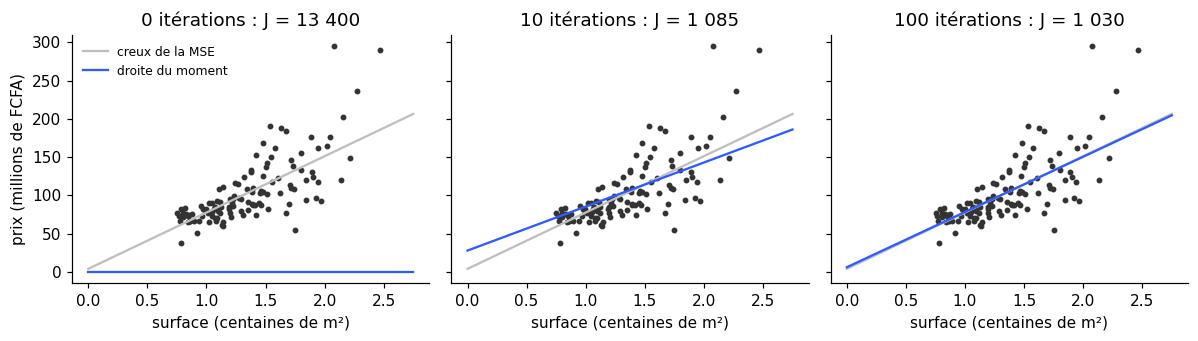

In [7]:
tirage = np.random.default_rng(11).choice(len(x), 120, replace=False)
bornes = np.array([0, 2.75])
figure, axes = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
for axe, k in zip(axes, (0, 10, 100)):
    w, b, j = historique[k]
    axe.scatter(x[tirage], y[tirage], s=8, color="0.2")
    axe.plot(bornes, predire(bornes, *historique[1000][:2]), color="0.75", label="creux de la MSE")
    axe.plot(bornes, predire(bornes, w, b), color="#2F5BFF", label="droite du moment")
    axe.set_title(f"{k} itérations : J = {j:,.0f}".replace(",", " "))
    axe.set_xlabel("surface (centaines de m²)")
axes[0].set_ylabel("prix (millions de FCFA)")
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()

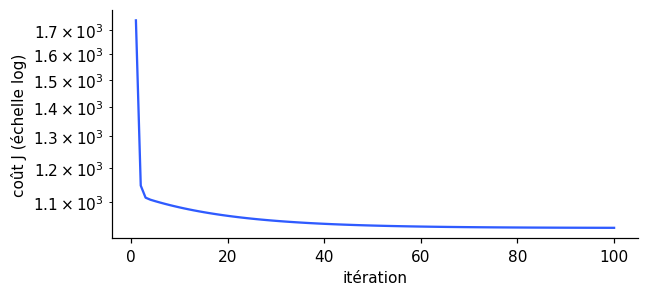

In [8]:
courbe = [historique[k][2] for k in range(1, 101)]
plt.figure(figsize=(6, 2.8))
plt.semilogy(range(1, 101), courbe, color="#2F5BFF")
plt.xlabel("itération")
plt.ylabel("coût J (échelle log)")
plt.tight_layout()

## 4. La formule directe et scikit-learn

Pour une droite, les moindres carrés donnent le creux sans itération. Les trois méthodes doivent s'accorder.

In [9]:
w_direct = np.sum((x - x.mean()) * (y - y.mean())) / np.sum((x - x.mean()) ** 2)
b_direct = y.mean() - w_direct * x.mean()

modele = LinearRegression().fit(x.reshape(-1, 1), y)

print(f"descente (1 000 itérations) : w = {historique[1000][0]:.3f}, b = {historique[1000][1]:.3f}")
print(f"formule directe             : w = {w_direct:.3f}, b = {b_direct:.3f}")
print(f"scikit-learn                : w = {modele.coef_[0]:.3f}, b = {modele.intercept_:.3f}")

assert np.allclose([w_direct, b_direct], [modele.coef_[0], modele.intercept_])
assert np.allclose(historique[1000][:2], [w_direct, b_direct], atol=0.05)

descente (1 000 itérations) : w = 73.599, b = 3.985
formule directe             : w = 73.599, b = 3.985
scikit-learn                : w = 73.599, b = 3.985


La descente est plus longue ici. Elle compte parce que la plupart des modèles suivants n'ont pas de formule directe.

Le coût reste à environ 1 030 : même la meilleure droite ne passe pas par toutes les ventes.

## 5. La limite : une relation courbe

Sur des points d'illustration tirés autour d'une courbe, la meilleure droite garde des écarts réguliers :
positifs aux deux bouts, négatifs au milieu.

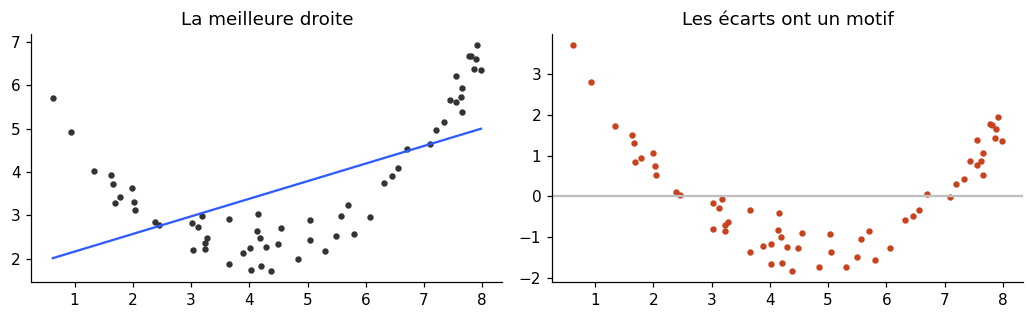

In [10]:
rng = np.random.default_rng(4)
xc = rng.uniform(0.3, 8.1, 60)
yc = 6.5 - 2.2 * xc + 0.28 * xc**2 + rng.normal(0, 0.35, 60)

droite = LinearRegression().fit(xc.reshape(-1, 1), yc)
residus = yc - droite.predict(xc.reshape(-1, 1))

figure, (gauche, milieu) = plt.subplots(1, 2, figsize=(9.5, 3))
ordre = np.argsort(xc)
gauche.scatter(xc, yc, s=10, color="0.2")
gauche.plot(xc[ordre], droite.predict(xc[ordre].reshape(-1, 1)), color="#2F5BFF")
gauche.set_title("La meilleure droite")
milieu.axhline(0, color="0.75")
milieu.scatter(xc, residus, s=10, color="#C8421E")
milieu.set_title("Les écarts ont un motif")
plt.tight_layout()

In [11]:
tiers = len(xc) // 3
bords = np.r_[residus[ordre[:tiers]], residus[ordre[-tiers:]]].mean()
centre = residus[ordre[tiers:-tiers]].mean()
print(f"écart moyen aux bouts : {bords:+.2f} ; au milieu : {centre:+.2f}")
assert bords > 0 > centre

écart moyen aux bouts : +0.60 ; au milieu : -1.20


## À vous

1. Essayez η = 0,5 puis η = 1. À partir de quelle valeur l'entraînement diverge-t-il ?
2. Ajoutez le nombre de chambres (`Bedroom AbvGr`) : c'est le sujet de l'épisode 12.

**Sources** : D2L 3.1, scikit-learn « Linear Models », Machine Learning Crash Course « Gradient descent »,
De Cock (2011), cours BCEAO du 27 octobre 2026.